# E3: Auxiliary Feature Integration Experiments

This notebook executes only E3.0–E3.4 with E2.5's fixed eight-feature core, LightGBM parameters, low-cardinality one-hot encoding and high-cardinality ordinal-as-numeric encoding. It does not rerun E2, select models/encoders, read test data, or perform leave-one-group-out ablation.

Shared `load_data`, `make_listing`, `load_auxiliary`, `make_auxiliary`, and `attach_auxiliary` remain in use. The independent E3 calendar-key lag helper maps macro source month s to listing month s+1 without filling gaps. January 2021 macro inputs remain NaN. Previous-month availability is assumed because publication timestamps are absent. HDB/POIs use a **Static Geographic Approximation**, not reconstructed historical operations. See the generated report for remaining point-in-time limitations.

In [1]:
import os
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / 'src').is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / 'src').is_dir()
sys.path.insert(0, str(PROJECT_ROOT))
from experiments.feature_engineering.utils.auxiliary import run_e3, plot_e3, RESULTS, FIGURES, GROUP_FEATURES, EXPERIMENTS
from IPython.display import display, Image
print('Feature groups:', GROUP_FEATURES)
print('Experiments:', EXPERIMENTS)


Feature groups: {'hdb': ['LATITUDE', 'LONGITUDE', 'MAX_FLOOR', 'SUBZONE', 'PLANNING_AREA'], 'mrt': ['mrt_distance_km', 'mrt_name', 'mrt_line_count'], 'schools': ['primary_school_distance_km', 'secondary_school_distance_km', 'schools_within_1km', 'schools_within_2km'], 'malls': ['mall_distance_km', 'mall_name'], 'coe': ['coe_sum'], 'stock': ['stock_index']}
Experiments: {'E3.0': (), 'E3.1': ('hdb',), 'E3.2': ('hdb', 'mrt'), 'E3.3': ('hdb', 'mrt', 'schools'), 'E3.4': ('hdb', 'mrt', 'schools', 'malls', 'coe', 'stock')}


## Execute fixed experiments

E3.0 must match E2.5's features, parameters, four metrics, row counts, labels, indices and saved validation predictions; otherwise execution stops before E3.1. Each join has an explicit feature whitelist and preserves source rows. Encoders fit only the training frame; predictions and metrics must be finite. Training time measures fit only.

In [2]:
results, audit = run_e3()
columns = ['experiment', 'feature_set', 'raw_feature_count', 'feature_count',
           'RMSE', 'MAE', 'R2', 'Mean Error', 'training_seconds',
           'control', 'delta_rmse', 'relative_improvement_pct']
display(results[columns])
print('E3.0 vs E2.5:', audit['e30_vs_e25'])
print('Availability assumption:', audit['availability_assumption'])
print('Stock source range used:', audit['stock_observation_range_used'])


/Users/wangyufan/Desktop/master/CS5228/project/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


E3.0 ordinal {'RMSE': 479.496863, 'MAE': 356.508969, 'R2': 0.470103, 'Mean Error': -45.033072}


/Users/wangyufan/Desktop/master/CS5228/project/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


E3.1 ordinal {'RMSE': 477.780134, 'MAE': 354.651906, 'R2': 0.473891, 'Mean Error': -45.476609}


/Users/wangyufan/Desktop/master/CS5228/project/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


...

E3.3 ordinal {'RMSE': 476.480489, 'MAE': 353.609287, 'R2': 0.476749, 'Mean Error': -46.23542}


/Users/wangyufan/Desktop/master/CS5228/project/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


E3.4 ordinal {'RMSE': 477.859261, 'MAE': 356.063195, 'R2': 0.473716, 'Mean Error': -53.630226}


,experiment,feature_set,raw_feature_count,feature_count,RMSE,MAE,R2,Mean Error,training_seconds,control,delta_rmse,relative_improvement_pct
0,E3.0,Core Only,8,53,479.496863,356.508969,0.470103,-45.033072,2.550462,E3.0,0.000000,0.000000
1,E3.1,Core + HDB,13,87,477.780134,354.651906,0.473891,-45.476609,2.138460,E3.0,1.716729,0.358027
2,E3.2,Core + HDB + MRT,16,90,476.602897,353.717023,0.476480,-45.217177,2.045255,E3.1,1.177238,0.246397
3,E3.3,Core + HDB + MRT + Schools,20,94,476.480489,353.609287,0.476749,-46.235420,2.273024,E3.2,0.122408,0.025683
4,E3.4,Core + HDB + MRT + Schools + Malls + COE + Stock,24,98,477.859261,356.063195,0.473716,-53.630226,2.232246,E3.3,-1.378772,-0.289366


E3.0 vs E2.5: {'RMSE_difference': 5.684341886080802e-14, 'MAE_difference': 0.0, 'R2_difference': 0.0, 'Mean Error_difference': 0.0, 'max_prediction_difference': 4.547473508864641e-13, 'passed': True}
Availability assumption: The previous complete calendar month is available at prediction time; exact release dates are not recorded.
Stock source range used: ['2021-01-04', '2025-02-28']


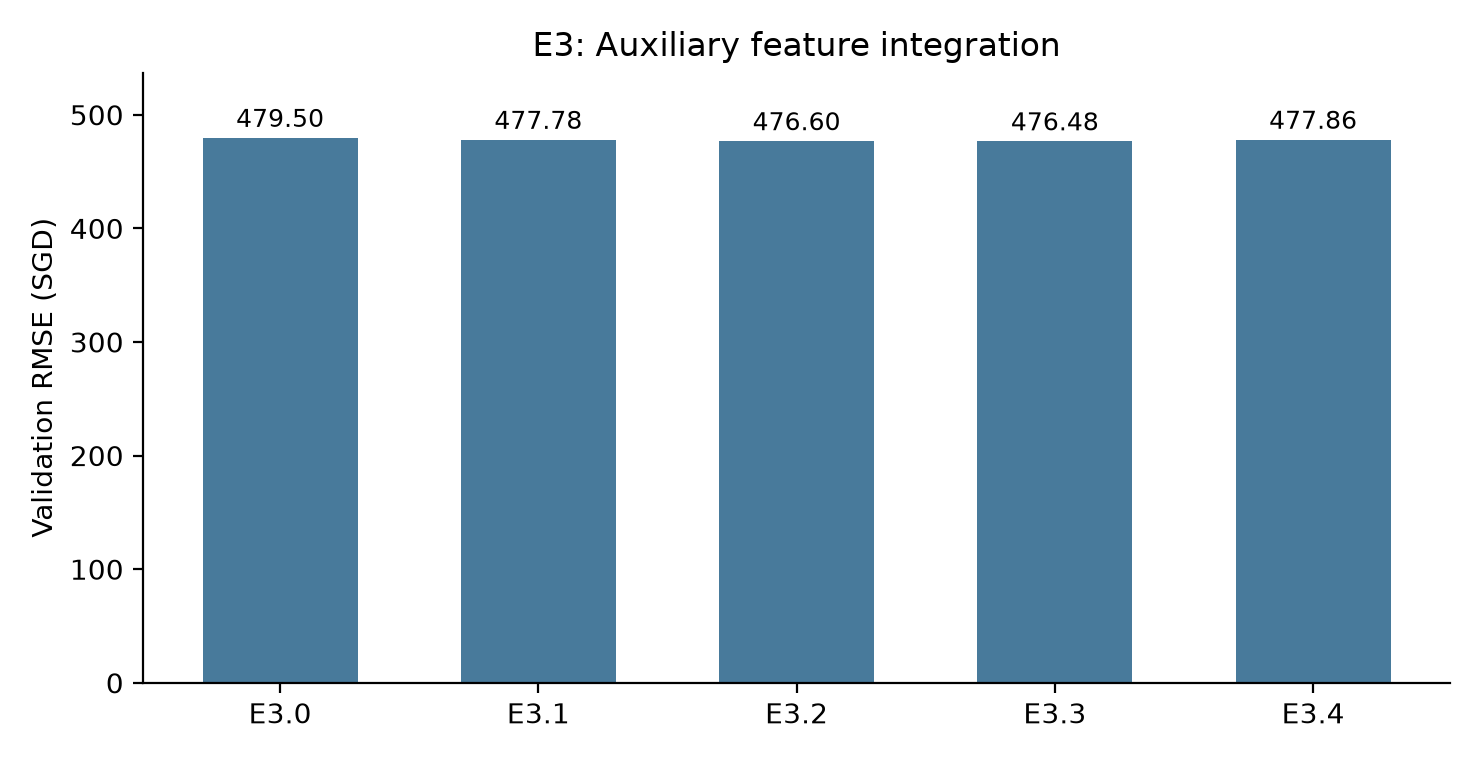

E3.4 vs E3.3: RMSE improvement = -1.378772 SGD (-0.289366%)
Malls, COE, and Stock enter together; no individual attribution is supported.


In [3]:
plot_e3(results)
display(Image(filename=str(FIGURES / 'e3_rmse_comparison.png')))
last = results.iloc[-1]
print(f"E3.4 vs E3.3: RMSE improvement = {last.delta_rmse:.6f} SGD ({last.relative_improvement_pct:.6f}%)")
print('Malls, COE, and Stock enter together; no individual attribution is supported.')
print('Final analysis:', PROJECT_ROOT / 'analysis/feature_engineering_results_zh.md')


## Interpretation limits

Positive deltas indicate improvement relative to the preceding stage (E3.0 is the zero-delta reference). A single validation period does not establish statistical significance or stability. One-month macro lagging does not verify exact publication delays or historical price vintages. Static MRT/school/mall snapshots can differ from historical operations. No further ablation is executed; inspect the results before deciding on follow-up work.